<a href="https://colab.research.google.com/github/yachna45/Olist-Ecommerce-BI-Analysis/blob/main/Olist_Ecommerce_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_708/1528833523.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_revenue, x='year_month_str', y='price', palette='Blues_r')


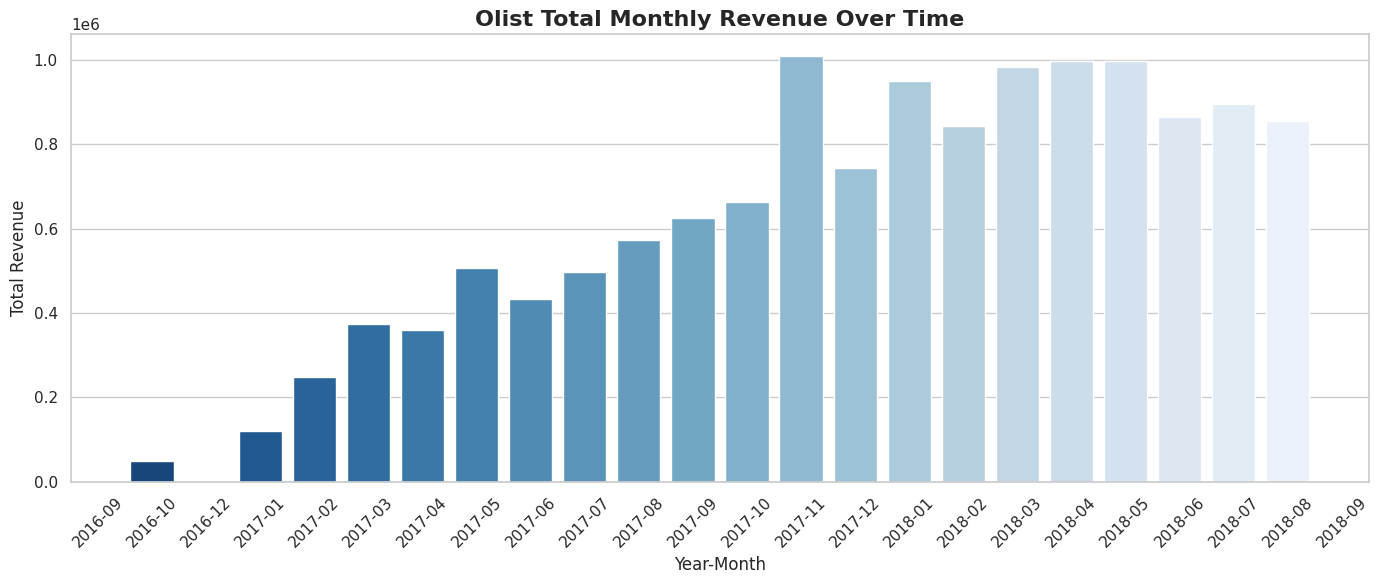

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



customers = pd.read_csv('olist_customers_dataset.csv')
geolocation = pd.read_csv('olist_geolocation_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
category_translation = pd.read_csv('product_category_name_translation.csv')


date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])


order_items = pd.merge(orders, items, on='order_id', how='inner')


order_items['year_month'] = order_items['order_purchase_timestamp'].dt.to_period('M')
monthly_revenue = order_items.groupby('year_month')['price'].sum().reset_index()


monthly_revenue['year_month_str'] = monthly_revenue['year_month'].astype(str)


sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

sns.barplot(data=monthly_revenue, x='year_month_str', y='price', palette='Blues_r')

plt.title('Olist Total Monthly Revenue Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
order_items_customers = pd.merge(order_items, customers, on='customer_id', how='inner')
state_revenue = order_items_customers.groupby('customer_state')['price'].sum().reset_index()
state_revenue = state_revenue.sort_values(by='price', ascending=False)

display(state_revenue.head(10))

,customer_state,price
25,SP,5202955.05
18,RJ,1824092.67
10,MG,1585308.03
22,RS,750304.02
17,PR,683083.76
23,SC,520553.34
4,BA,511349.99
6,DF,302603.94
8,GO,294591.95
7,ES,275037.31


/tmp/ipykernel_708/2297114726.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_revenue.head(10),


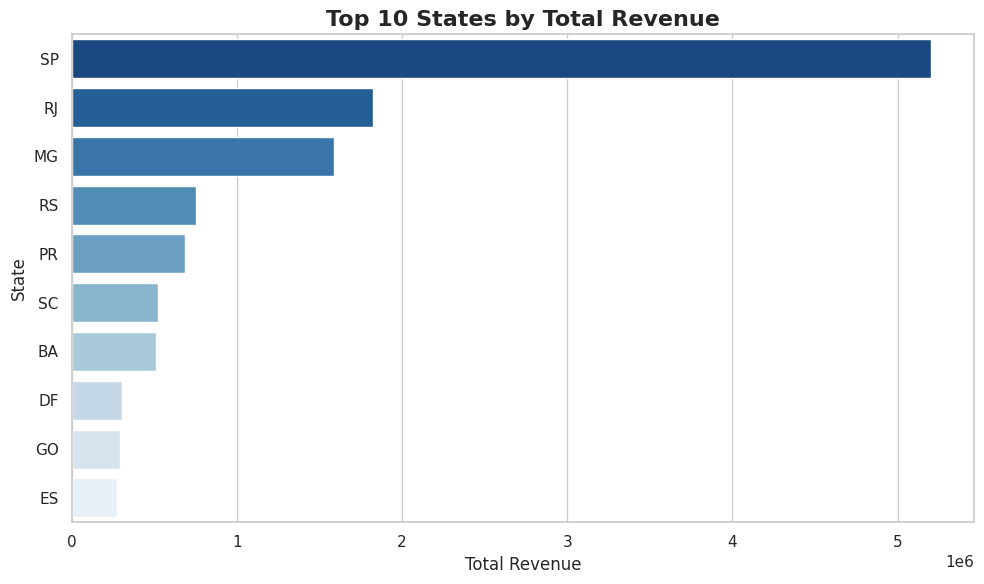

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(data=state_revenue.head(10),
            x='price',
            y='customer_state',
            palette='Blues_r')

plt.title('Top 10 States by Total Revenue', fontsize=16, fontweight='bold')
plt.xlabel('Total Revenue', fontsize=12)
plt.ylabel('State', fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
products_en = pd.merge(products, category_translation, on='product_category_name', how='left')
full_data = pd.merge(order_items_customers, products_en, on="product_id", how="inner")

category_revenue = full_data.groupby("product_category_name_english")["price"].sum().reset_index()
category_revenue = category_revenue.sort_values(by="price", ascending=False)

display(category_revenue.head(10))

,product_category_name_english,price
43,health_beauty,1258681.34
70,watches_gifts,1205005.68
7,bed_bath_table,1036988.68
65,sports_leisure,988048.97
15,computers_accessories,911954.32
39,furniture_decor,729762.49
20,cool_stuff,635290.85
49,housewares,632248.66
5,auto,592720.11
42,garden_tools,485256.46


/tmp/ipykernel_708/1741844571.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data= category_revenue.head(10),


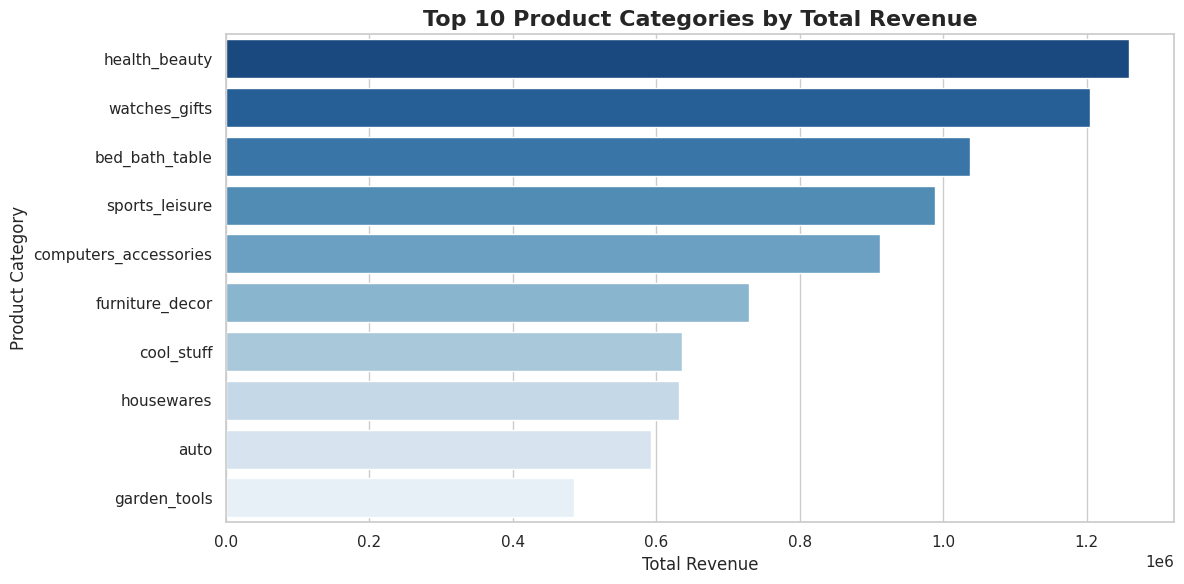

In [ ]:
plt.figure(figsize= (12, 6))

sns.barplot(data= category_revenue.head(10),
            x="price",
            y = "product_category_name_english",
            palette='Blues_r')


plt.title('Top 10 Product Categories by Total Revenue', fontsize=16, fontweight='bold')
plt.xlabel('Total Revenue', fontsize=12)
plt.ylabel('Product Category', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
reviews_data = pd.merge(full_data, reviews, on='order_id', how='inner')


reviews_data['order_delivered_customer_date'] = pd.to_datetime(reviews_data['order_delivered_customer_date'])
reviews_data['order_estimated_delivery_date'] = pd.to_datetime(reviews_data['order_estimated_delivery_date'])

reviews_data['delay_days'] = (reviews_data['order_delivered_customer_date'] - reviews_data['order_estimated_delivery_date']).dt.days


reviews_data['delivery_status'] = np.where(reviews_data['delay_days'] > 0, 'Late', 'On Time')


satisfaction_by_delay = reviews_data.groupby('delivery_status')['review_score'].mean().reset_index()

display(satisfaction_by_delay)

,delivery_status,review_score
0,Late,2.256572
1,On Time,4.152481


/tmp/ipykernel_708/4111917924.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = satisfaction_by_delay,


Text(0, 0.5, 'Average Review Score')

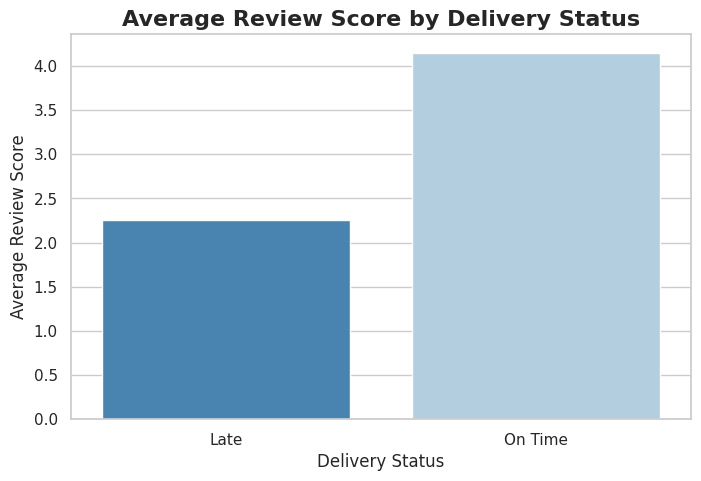

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(data = satisfaction_by_delay,
            x = "delivery_status",
            y= "review_score",
            palette = 'Blues_r')

plt.title('Average Review Score by Delivery Status', fontsize=16, fontweight='bold')
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Average Review Score', fontsize=12)